[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/01_what_is_md.ipynb)

# 01 · What Is Molecular Dynamics? Newton's Equations by Hand

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~45 min*

Molecular dynamics (MD) is a **computer microscope**: it moves every atom of a molecule step by step,
following Newton's laws, so you can watch a protein flex, a ligand sit in its pocket, or water
molecules jostle each other. Before using any MD software we will write a tiny MD engine ourselves in
about ten lines of NumPy. Everything later in the course (OpenMM, force fields, thermostats) is a
refinement of what you build here.

**Learning objectives.** By the end of this notebook you will be able to:

- explain how a potential energy function gives forces, and forces give motion
- write the velocity-Verlet integrator yourself and use it on a 1-D and a 2-D system
- see why a good integrator conserves energy and a naive one does not
- connect the timestep to the fastest vibration in a molecule (why MD uses femtoseconds)

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. The whole idea in three equations

Every atom $i$ has a position $\mathbf{r}_i$, a velocity $\mathbf{v}_i$, and a mass $m_i$. A **potential energy
function** $U(\mathbf{r}_1, \ldots, \mathbf{r}_N)$ (the *force field*, Notebook 02) says how much energy a given
arrangement of atoms has. Then:

$$\mathbf{F}_i = -\frac{\partial U}{\partial \mathbf{r}_i} \qquad \mathbf{a}_i = \frac{\mathbf{F}_i}{m_i} \qquad
\text{move the atoms a tiny time step } \Delta t \text{ and repeat.}$$

Atoms roll "downhill" on the energy surface, but they also carry momentum, so they overshoot, climb, and
oscillate. Repeating this millions of times gives a **trajectory**: a movie of the molecule.

We start with the simplest system there is: one particle on a spring, $U(x) = \tfrac12 k x^2$, whose exact
solution we know: $x(t) = x_0 \cos(\omega t)$ with $\omega = \sqrt{k/m}$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

k, m = 1.0, 1.0            # spring constant and mass (any consistent units)
omega = np.sqrt(k / m)
period = 2 * np.pi / omega

def harmonic_force(x):
    return -k * x           # F = -dU/dx for U = 0.5 k x^2

def energy(x, v):
    return 0.5 * m * v**2 + 0.5 * k * x**2   # kinetic + potential

print(f"angular frequency = {omega:.3f}, period = {period:.3f} time units")

angular frequency = 1.000, period = 6.283 time units


## 2. Two integrators: Euler vs velocity Verlet

The obvious way to step forward in time is **Euler's method**: use the current force to update the velocity,
and the current velocity to update the position. MD codes instead use **velocity Verlet**, which splits the
velocity update into two half-steps around the position update:

1. $v \leftarrow v + \tfrac{\Delta t}{2}\, F(x)/m$
2. $x \leftarrow x + \Delta t\, v$
3. $v \leftarrow v + \tfrac{\Delta t}{2}\, F(x)/m$ (with the force at the **new** position)

It costs the same (one force evaluation per step) but behaves completely differently over long times.

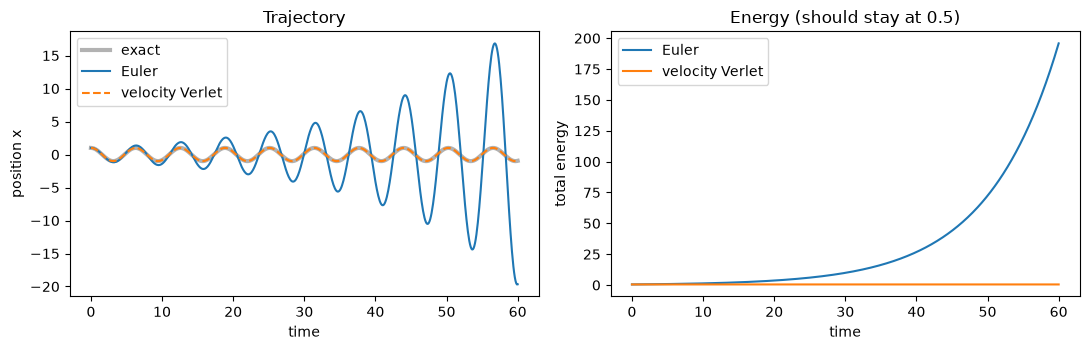

Euler:  energy grew from 0.500 to 195.792
Verlet: energy stays between 0.4988 and 0.5000


In [3]:
def euler(x, v, force, mass, dt, n_steps):
    xs, vs = [x], [v]
    for _ in range(n_steps):
        a = force(x) / mass
        x, v = x + dt * v, v + dt * a
        xs.append(x); vs.append(v)
    return np.array(xs), np.array(vs)

def velocity_verlet(x, v, force, mass, dt, n_steps):
    xs, vs = [x], [v]
    f = force(x)
    for _ in range(n_steps):
        v = v + 0.5 * dt * f / mass      # half kick
        x = x + dt * v                   # drift
        f = force(x)                     # new force (the expensive part in real MD)
        v = v + 0.5 * dt * f / mass      # half kick
        xs.append(x); vs.append(v)
    return np.array(xs), np.array(vs)

dt, n = 0.1, 600                          # 600 steps = about 9.5 periods
t = np.arange(n + 1) * dt
xe, ve = euler(1.0, 0.0, harmonic_force, m, dt, n)
xv, vv = velocity_verlet(1.0, 0.0, harmonic_force, m, dt, n)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t, np.cos(omega * t), "k-", lw=3, alpha=0.3, label="exact")
ax[0].plot(t, xe, label="Euler"); ax[0].plot(t, xv, "--", label="velocity Verlet")
ax[0].set(xlabel="time", ylabel="position x", title="Trajectory"); ax[0].legend()
ax[1].plot(t, energy(xe, ve), label="Euler"); ax[1].plot(t, energy(xv, vv), label="velocity Verlet")
ax[1].set(xlabel="time", ylabel="total energy", title="Energy (should stay at 0.5)"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Euler:  energy grew from 0.500 to {energy(xe[-1], ve[-1]):.3f}")
print(f"Verlet: energy stays between {energy(xv, vv).min():.4f} and {energy(xv, vv).max():.4f}")

Euler's energy grows without limit: the particle swings wider and wider, like a molecule that heats up by
itself and eventually explodes. Velocity Verlet's energy only wobbles slightly around the true value and
**never drifts**. This property (it is *time-reversible* and *symplectic*) is why Verlet-type integrators
are used in every MD code, including OpenMM, GROMACS, AMBER, and NAMD.

## 3. Why MD uses femtosecond time steps

Verlet is only stable if $\Delta t$ is small compared with the fastest oscillation period. For a harmonic
oscillator it becomes unstable at $\Delta t > 2/\omega$, and it is only *accurate* for much smaller steps.
In a molecule, the fastest motions are bonds to hydrogen. Let us estimate the C–H stretch period using real
force-field numbers (the AMBER CT–HC bond, $k = 284\,512$ kJ mol⁻¹ nm⁻²) in MD units:
nm, ps, atomic mass units, and kJ/mol, which combine without any conversion factors.

In [4]:
k_CH = 284512.0                       # kJ/mol/nm^2 (AMBER ff14SB CT-HC bond)
mu = 12.011 * 1.008 / (12.011 + 1.008)  # reduced mass of C-H in amu (g/mol)
omega_CH = np.sqrt(k_CH / mu)          # 1/ps
period_fs = 2 * np.pi / omega_CH * 1000
print(f"C-H stretch period: {period_fs:.1f} fs  ->  wavenumber {1e10 / (period_fs * 2.99792458e10 * 1e-5):.0f} cm^-1")
print(f"Verlet stability limit 2/omega = {2 / omega_CH * 1000:.1f} fs")

C-H stretch period: 11.4 fs  ->  wavenumber 2936 cm^-1
Verlet stability limit 2/omega = 3.6 fs


A C–H bond vibrates in about 11 fs (close to the ~3000 cm⁻¹ C–H stretch seen in IR spectra). To follow that
motion accurately you need roughly 10 or more steps per period, so classic MD uses **1 fs**. Constraining
bonds to hydrogen (Notebook 03) removes this fastest motion and allows **2 fs**, and heavier hydrogens allow
**4 fs**. A protein folding in a microsecond therefore needs 250 million to a billion steps, which is why MD
is computationally expensive.

## 4. A 2-D example: barriers and rare events

Real molecules have many minima (conformations) separated by energy barriers. Here is a particle on a 2-D
**double-well** surface $U(x, y) = (x^2 - 1)^2 + y^2$, with two minima at $x = \pm1$ separated by a barrier of
height 1 at $x = 0$. Our same Verlet function works for vectors without change.

low energy (E = 0.80): energy 0.8000-0.8000, barrier crossings: 0
high energy (E = 1.25): energy 1.2500-1.2503, barrier crossings: 10


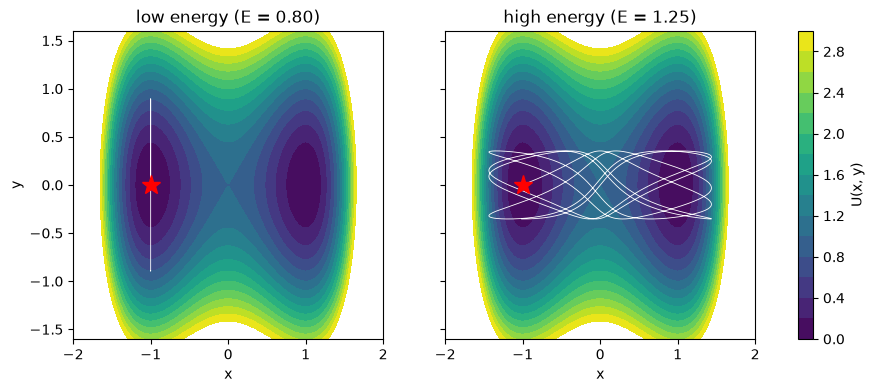

In [5]:
def U2(x, y):
    return (x**2 - 1)**2 + y**2

def force2(r):
    x, y = r
    return np.array([-4 * x * (x**2 - 1), -2 * y])

dt2, n2 = 0.01, 3000
runs = {}
for label, v0 in [("low energy (E = 0.80)", np.array([0.0, 1.2649])),
                  ("high energy (E = 1.25)", np.array([1.5, 0.5]))]:
    r, v = velocity_verlet(np.array([-1.0, 0.0]), v0, force2, 1.0, dt2, n2)
    runs[label] = r
    E = U2(r[:, 0], r[:, 1]) + 0.5 * (v**2).sum(axis=1)
    crossings = int(np.sum(np.diff(np.sign(r[:, 0])) != 0))
    print(f"{label}: energy {E.min():.4f}-{E.max():.4f}, barrier crossings: {crossings}")

X, Y = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-1.6, 1.6, 160))
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (label, r) in zip(ax, runs.items()):
    cs = a.contourf(X, Y, U2(X, Y), levels=np.linspace(0, 3, 16), cmap="viridis")
    a.plot(r[:, 0], r[:, 1], "w-", lw=0.6)
    a.plot(*r[0], "r*", ms=14)
    a.set(title=label, xlabel="x")
ax[0].set_ylabel("y"); fig.colorbar(cs, ax=ax, label="U(x, y)")
plt.show()

With total energy below the barrier, the particle can never leave its starting well. With more energy it hops
back and forth. In a real protein, thermal energy ($k_BT \approx 2.5$ kJ/mol at 300 K) is small compared with
many barriers, so transitions are **rare events**: you may need very long simulations, or enhanced sampling,
to see them. Keep this picture in mind for Notebooks 10 and 12.

## 5. What a real MD engine adds

Our toy engine has the same loop as OpenMM. Real engines add:

| You built | Real MD adds | Notebook |
|---|---|---|
| `force(x)` for a spring | a **force field**: bonds, angles, torsions, van der Waals, electrostatics | 02 |
| velocity Verlet | Langevin integrators, constraints, optimal timesteps | 03 |
| constant energy | **thermostats and barostats** for constant temperature and pressure | 04 |
| a particle in empty space | **periodic boxes**, cutoffs, and Ewald/PME electrostatics | 05 |
| one particle | tens of thousands of atoms, prepared from a PDB file | 06–08 |

### ✏️ Exercise 1

Find the timestep at which velocity Verlet becomes unstable for the harmonic oscillator. Run it for 1000
steps with `dt` = 1.0, 1.9, 2.0, and 2.1 and print the maximum $|x|$ reached. Compare with the theory, $\Delta t_{max} = 2/\omega$.

In [6]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
for dt_try in [1.0, 1.9, 2.0, 2.1]:
    x, v = velocity_verlet(1.0, 0.0, harmonic_force, m, dt_try, 1000)
    print(f"dt = {dt_try}: max |x| = {np.abs(x).max():.3g}")
# Stable (bounded) up to dt = 2/omega = 2; above it |x| grows exponentially.
```

</details>

### ✏️ Exercise 2

Measure **energy drift** for velocity Verlet on the 2-D double well: for `dt` = 0.005, 0.01, 0.05, and 0.1,
run 20 time units starting from `r = [-1, 0]`, `v = [1.5, 0.5]` and print the standard deviation of the total
energy. How does it scale with `dt`?

In [7]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
for dt_try in [0.005, 0.01, 0.05, 0.1]:
    r, v = velocity_verlet(np.array([-1.0, 0.0]), np.array([1.5, 0.5]), force2, 1.0, dt_try, int(20 / dt_try))
    E = U2(r[:, 0], r[:, 1]) + 0.5 * (v**2).sum(axis=1)
    print(f"dt = {dt_try}: std(E) = {E.std():.2e}")
# The fluctuation grows roughly as dt^2 (Verlet is a second-order method).
```

</details>

### ✏️ Exercise 3

Add **friction and random kicks** to turn the 2-D run into a simple Langevin thermostat (Notebook 04 does this
properly): after each step, multiply the velocity by `0.99` and add `np.random.normal(0, 0.1, 2)`. Start in the
left well with zero velocity and run 20,000 steps. Does the particle now cross the barrier on its own?

In [8]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
rng = np.random.default_rng(0)
r, v = np.array([-1.0, 0.0]), np.zeros(2)
xs = []
for _ in range(20000):
    v = v + 0.5 * dt2 * force2(r); r = r + dt2 * v; v = v + 0.5 * dt2 * force2(r)
    v = 0.99 * v + rng.normal(0, 0.1, 2)
    xs.append(r[0])
print("barrier crossings:", int(np.sum(np.diff(np.sign(xs)) != 0)))
```

</details>

## Key takeaways

- MD = forces from a potential energy function + Newton's equations, stepped forward in tiny time steps.
- Velocity Verlet is time-reversible: its energy fluctuates but does not drift. Euler's energy explodes.
- The fastest vibration (bonds to hydrogen, ~11 fs) limits the timestep to 1–4 fs.
- Barriers make conformational changes rare events, the central sampling problem of MD.

**Next:** [02 · Force fields explained](02_force_fields.ipynb).